# 08 — Run the best possession pipeline

This is the organiser-facing executable notebook. It runs the canonical `run_interpolated_flight_experiment.py` pipeline and evaluates the resulting visible-ball low-motion dead-ball candidate.

The pipeline is observation-first: engineered observations → scenario evidence → deterministic anchors → bounded transition hypotheses → final H/A/D/X labels. Kalman estimates missing-ball geometry only; it does not decide possession. Viterbi/HMM/HSMM remain optional decoder diagnostics, not the primary truth-maker.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUNNER = ROOT / 'possession_lab' / 'run_interpolated_flight_experiment.py'
RUNNER_MODULE = 'possession_lab.run_interpolated_flight_experiment'
EVALUATOR = ROOT / 'evaluation' / 'run_evaluation.py'
RESULTS = ROOT / 'evaluation' / 'results'
REPORTS = ROOT / 'evaluation' / 'reports'
BEST_NAME = 'Visible-ball low-motion dead-ball candidate'
BEST_OUTPUT = RESULTS / 'diagnostic_visible_ball_low_motion_dead_ball.csv'
configured_data_root = os.environ.get('MTAH_DATA_DIR')
data_candidates = [Path(configured_data_root)] if configured_data_root else []
data_candidates += [ROOT / 'data', ROOT.parent / 'barca-hack-repo-staging' / 'data']
DATA_ROOT = next((path for path in data_candidates if (path / 'tactical' / 'BAR-ATH_tactical_atd.txt').exists()), None)
assert RUNNER.exists(), RUNNER
assert EVALUATOR.exists(), EVALUATOR
assert DATA_ROOT is not None, f'tactical data not found in: {data_candidates}'
print('project root:', ROOT)
print('runner:', RUNNER)
print('data root:', DATA_ROOT)
print('candidate:', BEST_NAME)

project root: /Users/luke/Desktop/barca-hack-repo-staging
runner: /Users/luke/Desktop/barca-hack-repo-staging/possession_lab/run_interpolated_flight_experiment.py
data root: /Users/luke/Desktop/barca-hack-repo-staging/data
candidate: Visible-ball low-motion dead-ball candidate


## Execute the candidate pipeline

This cell regenerates the frame-aligned candidate and its diagnostic evidence files. No ground-truth labels are read by the runner.

In [2]:
runner_environment = os.environ.copy()
runner_environment['MTAH_DATA_DIR'] = str(DATA_ROOT)
pipeline = subprocess.run(
    [sys.executable, '-m', RUNNER_MODULE],
    cwd=ROOT,
    env=runner_environment,
    capture_output=True,
    text=True,
    check=False,
)
if pipeline.stdout:
    print(pipeline.stdout)
if pipeline.stderr:
    print('--- runner stderr ---')
    print(pipeline.stderr)
if pipeline.returncode != 0:
    raise RuntimeError(f'pipeline failed with exit code {pipeline.returncode}; see runner stderr above')
print('pipeline completed')
assert BEST_OUTPUT.exists(), BEST_OUTPUT
print('candidate written:', BEST_OUTPUT)

/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_scenario_bidirectional_interpolated_flight_ensemble.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_same_team_missing_ball_trajectory.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_same_team_kalman_missing_ball_trajectory.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_same_team_coordinate_path_bridge.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_same_player_dribble_gap_bridge.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_restart_type_specific_interpolated_flight.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_dead_ball_boundary_low_motion.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/diagnostic_visible_ball_low_motion_dead_ball.csv
/Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/baseline_switch_confirmation.c

## Public five-minute evaluation

The public labels are used after prediction for evaluation only. They cover frames 11185–18684; all other frames are ungraded `X`.

In [3]:
evaluation = subprocess.run(
    [sys.executable, str(EVALUATOR), '--gt', 'public'],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=True,
)
print('public evaluation completed')
scoreboard = pd.read_csv(ROOT / 'evaluation' / 'scoreboard.csv')
name_column = 'file' if 'file' in scoreboard.columns else 'submission'
candidate_rows = scoreboard[scoreboard[name_column].astype(str).str.contains('diagnostic_visible_ball_low_motion_dead_ball')]
display(candidate_rows)
assert not candidate_rows.empty, 'candidate is missing from the public scoreboard'

public evaluation completed


,rank,submission,status,reason,macro_f1,spell_f1_mean,poss,dur,n_gt_spells,gt_mean_spell_duration_s,...,n_pred_segments,fragmentation,n_graded,n_abstain_on_graded,trans_f1_12,trans_precision_12,trans_recall_12,trans_f1_25,trans_precision_25,trans_recall_25
0,1,diagnostic_visible_ball_low_motion_dead_ball,scored,NaN,0.888744,0.6,13,19.027692,17,14.190588,...,17,0.809524,7500,0,0.277778,0.3125,0.25,0.444444,0.5,0.4


## Transition and mislabel audit

This is an evaluation-only audit. It joins the public labels after the candidate exists, then reports interval errors and the scenario/transition evidence present at those frames. It does not feed labels back into the pipeline.

In [4]:
from possession_lab.mislabel_audit import build_mislabel_audit

audit = build_mislabel_audit(
    ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv',
    BEST_OUTPUT,
    REPORTS,
    scenario_path=REPORTS / 'scenario_confidence_scores.csv',
)
display(audit['summary'])
display(audit['runs'].sort_values('duration_frames', ascending=False).head(15))
display(audit['context_summary'].head(25))

,error_type,frames,gt_label,pred_label,runs,mean_run_frames,max_run_frames
4,H_TO_A,351,H,A,6,58.5,147
1,A_TO_H,242,A,H,5,48.4,106
2,D_TO_A,181,D,A,2,90.5,105
0,A_TO_D,50,A,D,4,12.5,20
3,D_TO_H,22,D,H,2,11.0,12


,error_run_id,start_frame,end_frame,duration_frames,error_type,gt_label,pred_label
0,0,11351,11497,147,H_TO_A,H,A
10,10,15656,15761,106,A_TO_H,A,H
12,12,15889,15993,105,D_TO_A,D,A
14,14,17293,17379,87,H_TO_A,H,A
15,15,17380,17455,76,D_TO_A,D,A
1,1,11553,11623,71,A_TO_H,A,H
7,7,13785,13825,41,H_TO_A,H,A
11,11,15766,15798,33,H_TO_A,H,A
8,8,14846,14875,30,A_TO_H,A,H
3,3,12805,12830,26,A_TO_H,A,H


,error_type,context_value,frames,context_dimension
22,H_TO_A,CONTESTED,131,scenario_context_causal
28,H_TO_A,UNKNOWN,105,scenario_context_causal
17,D_TO_A,UNKNOWN,93,scenario_context_causal
5,A_TO_H,BALL_IN_FLIGHT,88,scenario_context_causal
13,D_TO_A,BALL_IN_FLIGHT,70,scenario_context_causal
10,A_TO_H,RECEPTION_CANDIDATE,56,scenario_context_causal
6,A_TO_H,CONTESTED,36,scenario_context_causal
25,H_TO_A,PRESSURED_CONTROL,34,scenario_context_causal
21,H_TO_A,BALL_IN_FLIGHT,27,scenario_context_causal
7,A_TO_H,CONTROLLED,26,scenario_context_causal


## Where the model went wrong

The candidate is evaluated first, then its public disagreements are inspected. These windows are not training input. They show where the predicted H/A/D path differs from the supplied public label and which observable scenario, anchor, and missing-ball context were present around the error.

The windows below are ranked by contiguous disagreement duration. Grey shading marks frames outside the public graded range; orange shading marks missing-ball observations.

,start_frame,end_frame,duration_frames,duration_s
0,17293,17455,163,6.52
1,11351,11497,147,5.88
2,15656,15761,106,4.24
3,15889,15993,105,4.20
4,11553,11623,71,2.84
5,12805,12850,46,1.84
6,13785,13825,41,1.64
7,15766,15798,33,1.32
8,14846,14875,30,1.20
9,13680,13703,24,0.96


public disagreement windows: 17; wrong graded frames: 846


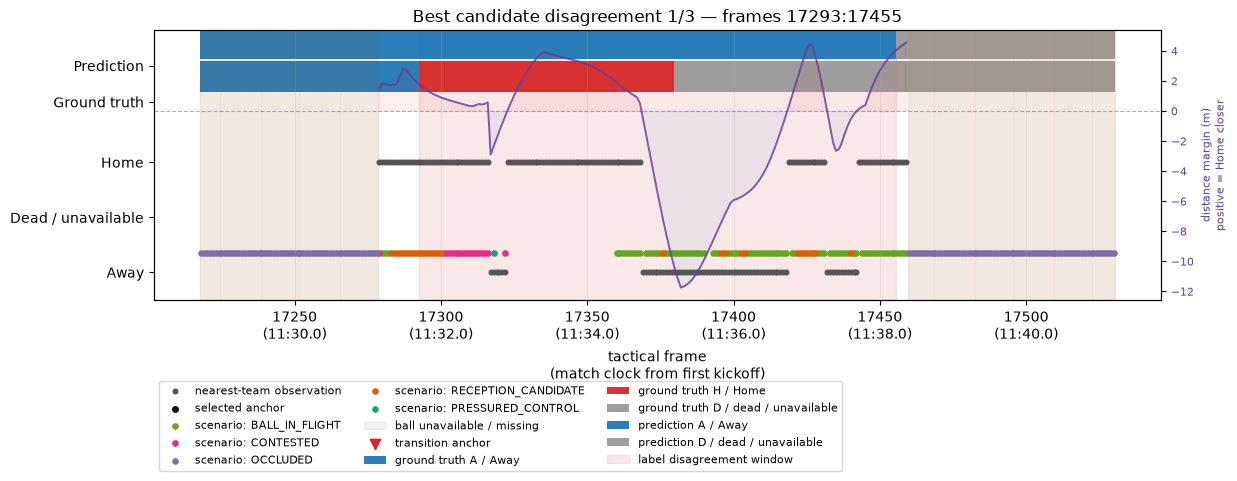

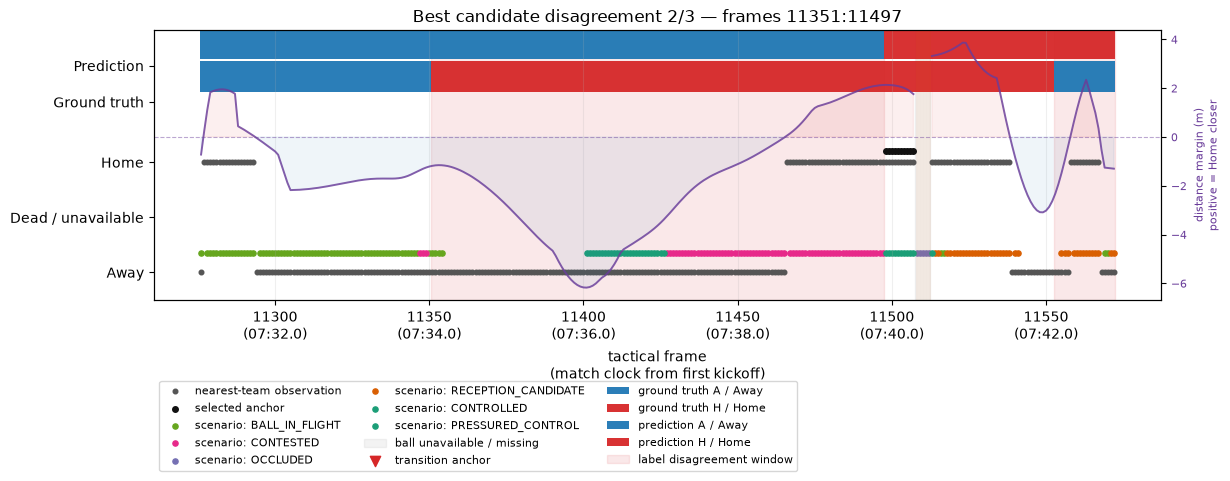

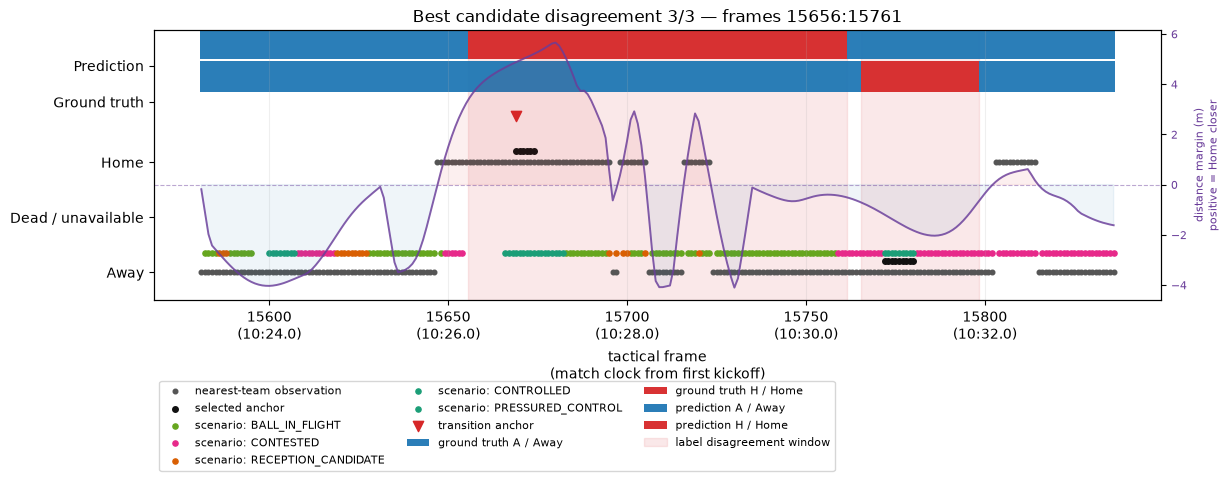

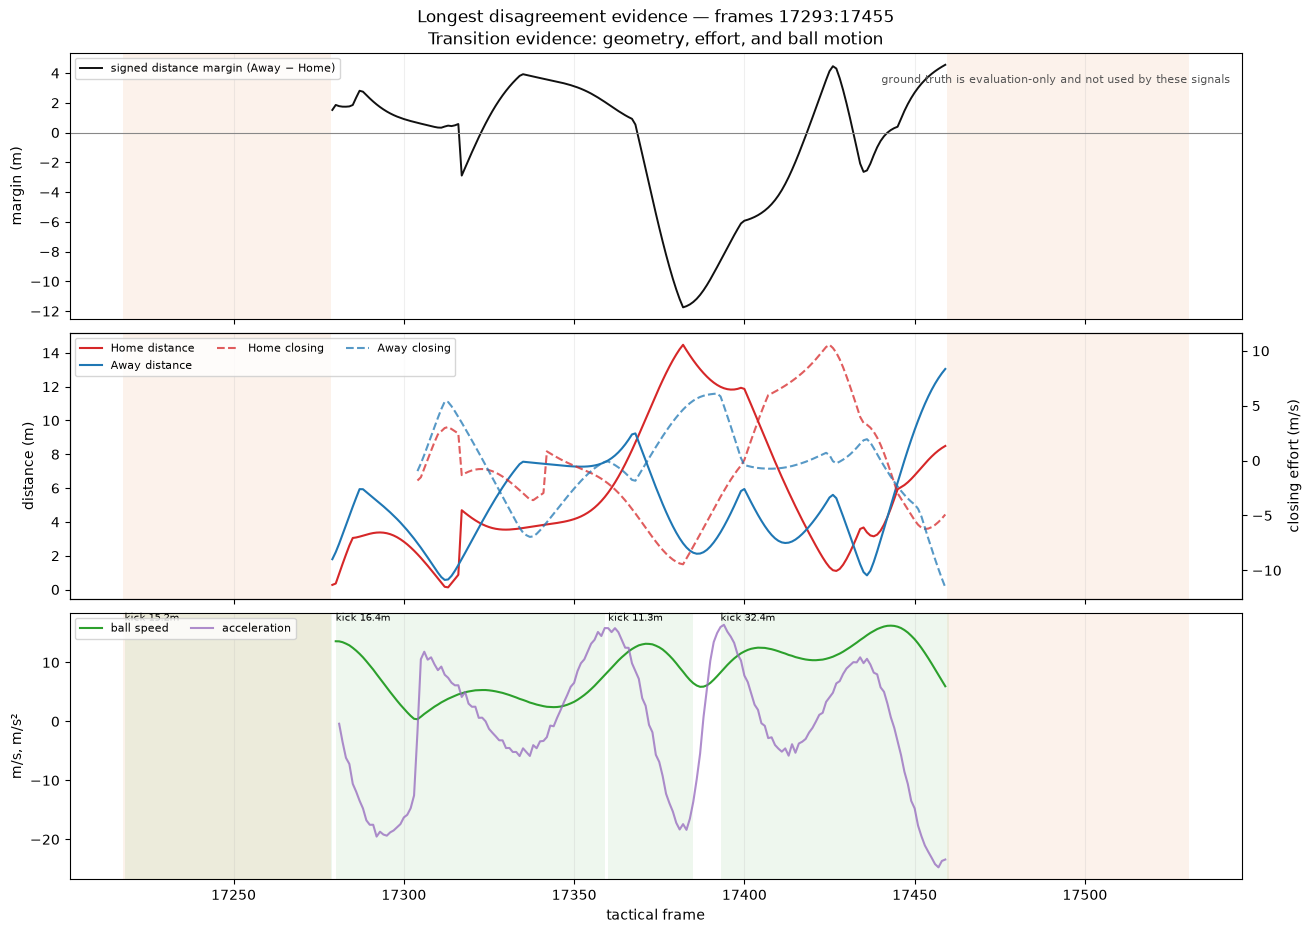

In [5]:
from IPython.display import display
from possession_lab.calculations.features import build_engineered_features
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.temporal_rules import load_rules
from possession.calculations.plotting import plot_timeline_window
from possession_lab.calculations.plotting import plot_transition_signals_window
import matplotlib.pyplot as plt
import numpy as np

# Rebuild the same observation table used by the runner for plotting only.
# Public labels enter after prediction and never modify these features.
os.environ['MTAH_DATA_DIR'] = str(DATA_ROOT)
plot_features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())
ground_truth = pd.read_csv(ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv')
prediction = pd.read_csv(BEST_OUTPUT)
gt_by_frame = pd.Series(ground_truth['label'].astype(str).str.upper().to_numpy(), index=ground_truth['frame'].astype(int))
pred_by_frame = pd.Series(prediction['label'].astype(str).str.upper().to_numpy(), index=prediction['frame'].astype(int))
graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
mismatch_frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
if len(mismatch_frames) == 0:
    print('No public disagreement windows found.')
else:
    groups = np.split(mismatch_frames, np.where(np.diff(mismatch_frames) > 1)[0] + 1)
    mismatch_windows = sorted(((int(group[0]), int(group[-1])) for group in groups), key=lambda pair: pair[1] - pair[0], reverse=True)
    window_table = pd.DataFrame(mismatch_windows, columns=['start_frame', 'end_frame'])
    window_table['duration_frames'] = window_table['end_frame'] - window_table['start_frame'] + 1
    window_table['duration_s'] = window_table['duration_frames'] / 25.0
    display(window_table.head(10))
    print(f'public disagreement windows: {len(window_table)}; wrong graded frames: {len(mismatch_frames)}')
    context_frames = 75
    for number, (window_start, window_end) in enumerate(mismatch_windows[:3], start=1):
        left = max(int(plot_features['frame'].min()), window_start - context_frames)
        right = min(int(plot_features['frame'].max()), window_end + context_frames)
        figure, axis = plot_timeline_window(plot_features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
        axis.set_title(f'Best candidate disagreement {number}/3 — frames {window_start}:{window_end}')
        plt.show()
    window_start, window_end = mismatch_windows[0]
    left = max(int(plot_features['frame'].min()), window_start - context_frames)
    right = min(int(plot_features['frame'].max()), window_end + context_frames)
    figure, axes = plot_transition_signals_window(plot_features, left, right, ground_truth=gt_by_frame)
    figure.suptitle(f'Longest disagreement evidence — frames {window_start}:{window_end}', y=1.02)
    plt.show()

## Outputs to present

- Candidate submission: `evaluation/results/diagnostic_visible_ball_low_motion_dead_ball.csv`
- Public scoreboard: `evaluation/scoreboard.csv`
- Transition ledger: `evaluation/reports/diagnostic_visible_ball_low_motion_dead_ball_transitions.csv`
- Scenario/trust evidence: `evaluation/reports/scenario_confidence_scores.csv`
- Mislabel intervals: `evaluation/reports/visible_ball_mislabel_runs.csv`

The first-half hand-labelled reference remains a separate diagnostic experiment in `10_first_half_results.ipynb`; it is not used as the presentation benchmark.